In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

In [2]:
file_path= "concrete+compressive+strength/Concrete_Data.xls"
df= pd.read_excel(file_path)

print(df.shape)
df.head()

(1030, 9)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
X= df.iloc[:,:8]
y= df.iloc[:,8]

print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (1030, 8)
y shape: (1030,)


In [4]:
train_idx= np.r_[0:500, 630:1030]
X_train= X.iloc[train_idx].copy()
y_train= y.iloc[train_idx].copy()
X_test= X[500:630]
y_test= y[500:630]

print("Training:",X_train.shape,y_train.shape)
print("Testing:",X_test.shape,y_test.shape)

Training: (900, 8) (900,)
Testing: (130, 8) (130,)


In [5]:
import numpy as np

def gradient_descent(X,y,lr,max_iter,tol):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    n=X.shape[0]
    X = np.c_[np.ones(n), X]
    beta= np.zeros(X.shape[1])
    mse_history = []
    prev_mse=np.inf
    for i in range(max_iter):
        pred=X@beta
        errors=pred-y
        gradient=(2/n)*X.T@ errors
        beta=beta-lr*gradient
        pred=X@beta
        current_mse=np.mean((y-pred)**2)
        mse_history.append(current_mse)
        if not np.isfinite(current_mse):
            break
        if abs(prev_mse-current_mse)<tol:
            break
        prev_mse=current_mse
    r_squared = (1-current_mse/np.var(y) if np.var(y) > 0 else np.nan)
    return beta, mse_history

def predict(X,beta):
    X_1= np.c_[np.ones(X.shape[0]), X]
    return X_1@beta

def evaluate(y,y_pred):
    mse=np.mean((y_pred-y)**2)
    r_squared=1-mse/np.var(y)
    return mse, r_squared

## Feature Transformation

In [6]:
mean= X_train.mean(axis=0)
std= X_train.std(axis=0)
std= np.where(std==0,1,std)
X_train_stand= (X_train-mean)/std
X_test_stand= (X_test-mean)/std


X_train_log= np.log1p(X_train)
X_test_log= np.log1p(X_test)


In [7]:
beta_log, losses_log = gradient_descent(
    X_train_log, y_train,
    lr=0.001,
    max_iter=10000,
    tol=0.0000001
)
mse, r2 = evaluate(y_test, predict(X_test_log, beta_log))
print(f"Log-transformed: Test MSE = {mse:.4f}, R² = {r2:.4f}")


Log-transformed: Test MSE = 55.5716, R² = 0.7517


## Q3 Scaling

In [23]:
#Q3.1 train a multivariate model using untransformed features

lr_untrans=5e-8
iter=10000

beta_raw, loss_raw = gradient_descent(
    X_train.values, y_train.values, lr_untrans, max_iter=iter,tol=1e-6
)

train_mse, train_r2 = evaluate(
    y_train.values, predict(X_train.values, beta_raw)
)
test_mse, test_r2 = evaluate(
    y_test.values, predict(X_test.values, beta_raw)
)

print("Untransformed Model")
print(f"Train: MSE = {train_mse:.4f}, R² = {train_r2:.4f}")
print(f"Test:  MSE = {test_mse:.4f}, R² = {test_r2:.4f}")

Untransformed Model
Train: MSE = 115.6933, R² = 0.5824
Test:  MSE = 152.0167, R² = 0.3207


In [25]:
#Q3.1 train a multivariate model using standardized features

lr_stand=0.01
iter=10000

beta_stand, loss_stand = gradient_descent(
    X_train_stand, y_train.values, lr_stand, iter, tol=1e-6
)

train_mse_stand, train_r2_stand = evaluate(
    y_train.values, predict(X_train_stand, beta_stand)
)
test_mse_stand, test_r2_stand = evaluate(
    y_test.values, predict(X_test_stand, beta_stand)
)

print("Standardized Model")
print(f"Train: MSE = {train_mse_stand:.4f}, R² = {train_r2_stand:.4f}")
print(f"Test:  MSE = {test_mse_stand:.4f}, R² = {test_r2_stand:.4f}")

Standardized Model
Train: MSE = 104.1447, R² = 0.6240
Test:  MSE = 141.0856, R² = 0.3695


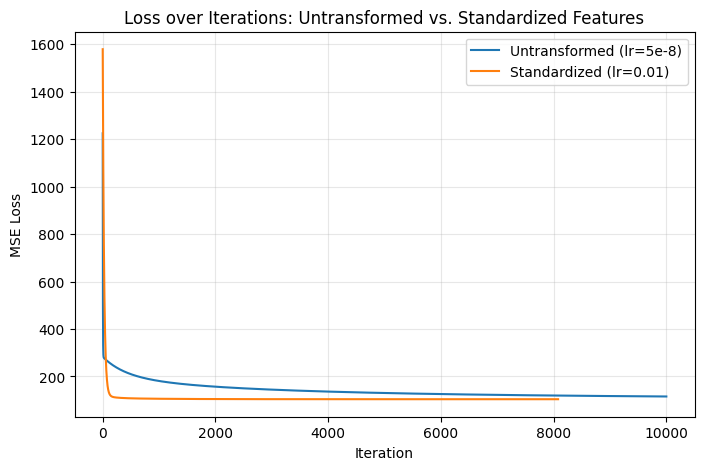

In [26]:
#Q3.1 plot

plt.figure(figsize=(8, 5))
plt.plot(loss_raw, label="Untransformed (lr=5e-8)")
plt.plot(loss_stand, label="Standardized (lr=0.01)")

plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Loss over Iterations: Untransformed vs. Standardized Features")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("scaling_convergence.png", dpi=300, bbox_inches="tight")
plt.show()

## Q4

In [15]:
#Q4 no scaling model using linear regression package
from sklearn.linear_model import LinearRegression

#fitting
model_unscaled = LinearRegression()
model_unscaled.fit(X_train, y_train)

#prediction and metrics
y_train_pred_unscaled = model_unscaled.predict(X_train)
y_test_pred_unscaled = model_unscaled.predict(X_test)
train_mse_unscaled = np.mean((y_train_pred_unscaled - y_train)**2)
train_r2_unscaled = model_unscaled.score(X_train, y_train)
test_mse_unscaled = np.mean((y_test_pred_unscaled - y_test)**2)
test_r2_unscaled = model_unscaled.score(X_test, y_test)

print("Training MSE is:", train_mse_unscaled)
print("Training R^2 is :", train_r2_unscaled)
print("Testing MSE is:", test_mse_unscaled)
print("Testing R^2 is:", test_r2_unscaled)

Training MSE is: 104.14373897310753
Training R^2 is : 0.6240495572262081
Testing MSE is: 141.3138647083901
Testing R^2 is: 0.3684829048435455


## Q5

In [28]:
lr_log = 0.001
iter = 10000

beta_log, loss_log = gradient_descent(
    X_train_log, y_train.values, lr_log, max_iter=10000, tol=1e-6
)

train_mse_log, train_r2_log = evaluate(
    y_train.values, predict(X_train_log, beta_log)
)
test_mse_log, test_r2_log = evaluate(
    y_test.values, predict(X_test_log, beta_log)
)

print("Log-Transformed Model")
print(f"Train: MSE = {train_mse_log:.4f}, R² = {train_r2_log:.4f}")
print(f"Test:  MSE = {test_mse_log:.4f}, R² = {test_r2_log:.4f}")

Log-Transformed Model
Train: MSE = 66.5257, R² = 0.7598
Test:  MSE = 55.5716, R² = 0.7517


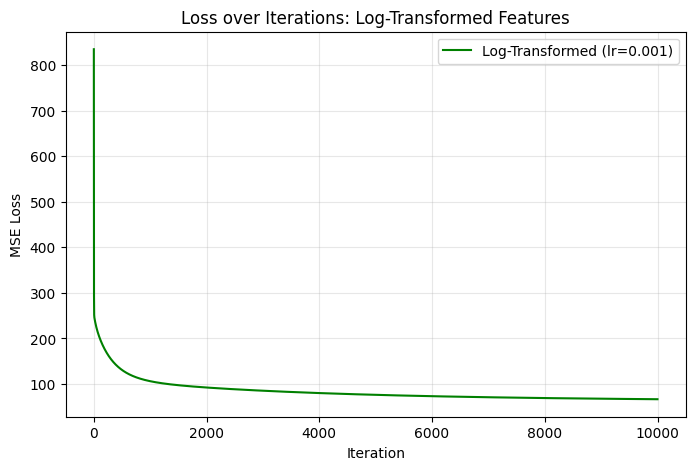

In [29]:
# Q5.1 figure showing loss over iterations

plt.figure(figsize=(8, 5))
plt.plot(loss_log, color="green", label="Log-Transformed (lr=0.001)")

plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Loss over Iterations: Log-Transformed Features")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("5104_Q5.1.png", dpi=300, bbox_inches="tight")
plt.show()

In [30]:
# Table 1. Descriptive Statistics

train_data = X_train.copy()
train_data["Compressive Strength"] = y_train

summary = train_data.agg(["mean", "std", "min", "max"]).T
summary.columns = ["Mean", "SD", "Min", "Max"]
summary.index = [
    "Cement", "Blast Furnace Slag", "Fly Ash", "Water",
    "Superplasticizer", "Coarse Aggregate", "Fine Aggregate",
    "Age", "Compressive Strength"
]

display(summary.round(2))
summary.round(2).to_csv("Table1_Descriptive_Statistics.csv")

,Mean,SD,Min,Max
Cement,277.87,106.00,102.00,540.0
Blast Furnace Slag,76.11,84.07,0.00,305.3
Fly Ash,57.38,64.26,0.00,200.1
Water,180.72,22.28,121.75,247.0
Superplasticizer,6.86,5.98,0.00,32.2
Coarse Aggregate,973.76,77.57,801.00,1145.0
Fine Aggregate,772.33,81.91,594.00,992.6
Age,46.04,61.32,1.00,365.0
Compressive Strength,36.93,16.65,2.33,82.6


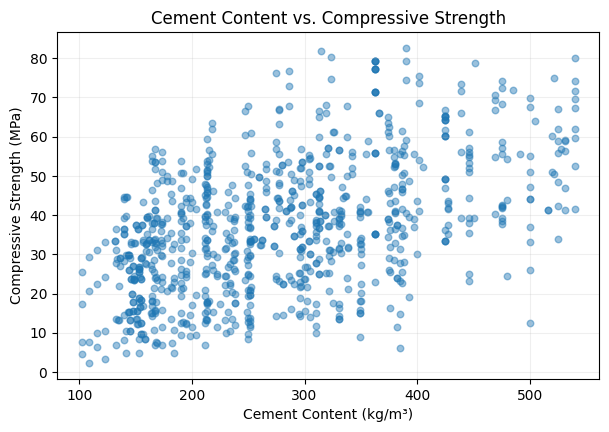

In [31]:
# Figure 1. Cement Content vs. Compressive Strength

plt.figure(figsize=(7, 4.5))
plt.scatter(X_train.iloc[:, 0], y_train, alpha=0.45, s=22)

plt.xlabel("Cement Content (kg/m³)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Cement Content vs. Compressive Strength")
plt.grid(alpha=0.2)

plt.show()

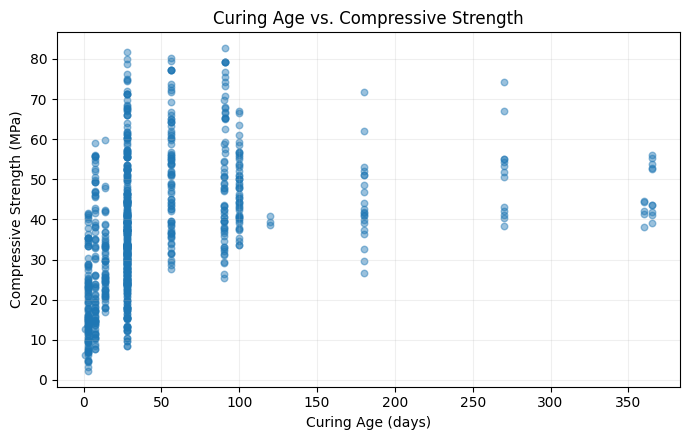

In [32]:
# Figure 2. Curing Age vs. Compressive Strength

plt.figure(figsize=(7, 4.5))
plt.scatter(X_train.iloc[:, 7], y_train, alpha=0.45, s=22)

plt.xlabel("Curing Age (days)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Curing Age vs. Compressive Strength")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

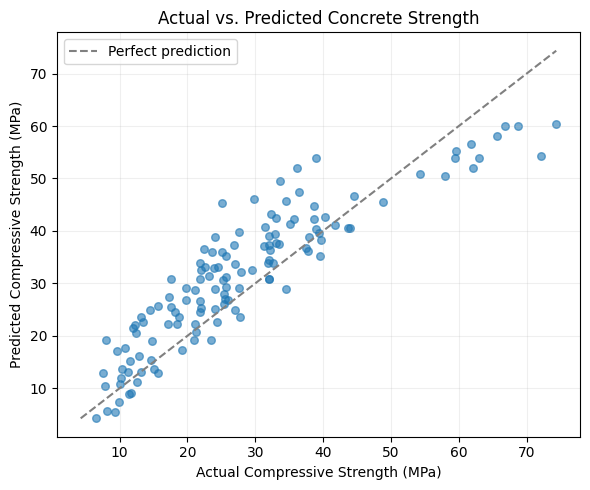

In [33]:
# Figure 3. Actual vs. Predicted Concrete Strength

y_pred = model_log.predict(np.log1p(X_test))

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.6, s=30)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "--", color="gray", label="Perfect prediction")

plt.xlabel("Actual Compressive Strength (MPa)")
plt.ylabel("Predicted Compressive Strength (MPa)")
plt.title("Actual vs. Predicted Concrete Strength")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

In [16]:
#Q5.3 log transformation model using linear regression package
#log transformation and fitting
X_train_log = np.log1p(X_train)
X_test_log = np.log1p(X_test)
model_log = LinearRegression()
model_log.fit(X_train_log, y_train)
y_train_pred_log = model_log.predict(X_train_log)
y_test_pred_log = model_log.predict(X_test_log)

# Training metrics
train_mse_log = np.mean((y_train_pred_log - y_train) ** 2)
train_r2_log = model_log.score(X_train_log, y_train)

# testing metrics
test_mse_log = np.mean((y_test_pred_log - y_test) ** 2)
test_r2_log = model_log.score(X_test_log, y_test)

# Print results
print("Training MSE is:", train_mse_log)
print("Training R^2 is:", train_r2_log)

print("Testing MSE is:", test_mse_log)
print("Testing R^2 is:", test_r2_log)

Training MSE is: 55.832418235002386
Training R^2 is: 0.7984495029317041
Testing MSE is: 54.38490724351401
Testing R^2 is: 0.7569594553680191


## Q6.1

In [18]:
#Q6.1 which models are easy to train
results = {}
best_results = []

for column in X_train.columns:
    X_train_one = X_train[[column]].values
    X_test_one = X_test[[column]].values
    # intercept
    X_aug = np.c_[np.ones(X_train_one.shape[0]), X_train_one]
    n = len(y_train)
    lambda_max = np.linalg.eigvalsh(X_aug.T @X_aug).max()
    lr_max = n / lambda_max

    learning_rates_one = lr_max * np.geomspace(
        1e-4, 0.9, 20)
    
    train_r2_list = []
    test_r2_list = []
    
    for lr in learning_rates_one:
        beta, losses = gradient_descent(
            X_train_one,
            y_train.values,
            lr=lr,
            max_iter=10000,
            tol=1e-6)

        y_train_pred = predict(X_train_one, beta)
        y_test_pred = predict(X_test_one, beta)

        train_mse, train_r2 = evaluate(
            y_train.values,
            y_train_pred
        )

        test_mse, test_r2 = evaluate(
            y_test.values,
            y_test_pred
        )

        train_r2_list.append(train_r2)
        test_r2_list.append(test_r2)

    results[column] = {
        "learning_rates": learning_rates_one,
        "train_r2": train_r2_list,
        "test_r2": test_r2_list
    }
    best_index = np.argmax(test_r2_list)
    best_results.append({
        "Feature": column,
        "Best Learning Rate": learning_rates_one[best_index],
        "Training R^2": train_r2_list[best_index],
        "Testing R^2": test_r2_list[best_index]
    })

#printing best possible learning rate that gives highest R^2
best_table = pd.DataFrame(best_results)
display(best_table)

,Feature,Best Learning Rate,Training R^2,Testing R^2
0,Cement (component 1)(kg in a m^3 mixture),1.130781e-09,0.075154,0.235421
1,Blast Furnace Slag (component 2)(kg in a m^3 m...,7.001820e-05,-0.481904,-0.877979
2,Fly Ash (component 3)(kg in a m^3 mixture),7.514027e-05,-0.560985,0.180940
3,Water (component 4)(kg in a m^3 mixture),3.016108e-09,-0.307655,-0.174241
4,Superplasticizer (component 5)(kg in a m^3 mix...,2.333941e-04,0.075196,0.245523
5,Coarse Aggregate (component 6)(kg in a m^3 mi...,1.047979e-10,-0.164410,-0.251865
6,Fine Aggregate (component 7)(kg in a m^3 mixture),1.657851e-10,-0.212237,-0.191606
7,Age (day),1.531589e-04,0.074230,-0.270712


In [20]:
#Q4 standardization model using linear regression package

#standardization
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_train_std = (X_train - X_mean)/ X_std
X_test_std = (X_test - X_mean)/ X_std

#fitting
model_std = LinearRegression()
model_std.fit(X_train_std, y_train)

#prediction and metrics
y_train_pred_std = model_std.predict(X_train_std)
y_test_pred_std = model_std.predict(X_test_std)
train_mse_std = np.mean((y_train_pred_std - y_train)** 2)
train_r2_std = model_std.score(X_train_std, y_train)
test_mse_std = np.mean((y_test_pred_std - y_test)** 2)
test_r2_std = model_std.score(X_test_std, y_test)

print("Training MSE is:", train_mse_std)
print("Training R^2 is:", train_r2_std)
print("Testing MSE is:", test_mse_std)
print("Testing R^2 is:", test_r2_std)

Training MSE is: 104.14373897310753
Training R^2 is: 0.6240495572262081
Testing MSE is: 141.3138647083901
Testing R^2 is: 0.3684829048435455


In [21]:
summary_table = pd.DataFrame({
    "Model": [
        "Untransformed",
        "Standardized",
        "Log-Transformed"],
    "Training MSE": [
        train_mse_unscaled,
        train_mse_std,
        train_mse_log],
    "Testing MSE": [
        test_mse_unscaled,
        test_mse_std,
        test_mse_log],
    "Training R^2": [
        train_r2_unscaled,
        train_r2_std,
        train_r2_log],
    "Testing R^2": [
        test_r2_unscaled,
        test_r2_std,
        test_r2_log]
})

print(summary_table)

             Model  Training MSE  Testing MSE  Training R^2  Testing R^2
0    Untransformed    104.143739   141.313865       0.62405     0.368483
1     Standardized    104.143739   141.313865       0.62405     0.368483
2  Log-Transformed     55.832418    54.384907       0.79845     0.756959


## Q6.2

In [ ]:
results = []

for j, name in enumerate(X.columns):
    X_one = X_one = X_train.iloc[:, [j]].to_numpy(dtype=float)

    # Choose a stable learning rate using this training feature
    X_bias = np.c_[np.ones(len(X_one)), X_one]
    largest_eigenvalue = np.linalg.eigvalsh(
        (2 / len(y_train)) * X_bias.T @ X_bias
    )[-1]
    lr = 1 / largest_eigenvalue

    beta, losses = gradient_descent(
        X_one, y_train, lr=lr, max_iter=10000,tol=1e-6
    )

    train_pred = predict(X_one, beta)
    test_pred = predict(X_test.iloc[:, [j]].to_numpy(dtype=float), beta)

    train_mse, train_r2 = evaluate(y_train, train_pred)
    test_mse, test_r2 = evaluate(y_test, test_pred)

    # R² > 0 exactly when MSE < variance of y
    positive_steps = np.flatnonzero(
        np.asarray(losses) < np.var(y_train)
    )

    results.append({
        "Feature": name,
        "Learning rate": lr,
        "Training MSE": train_mse,
        "Training R²": train_r2,
        "Testing MSE": test_mse,
        "Testing R²": test_r2
    })

results_df = pd.DataFrame(results)
display(results_df)

print("Models with positive training R²:",
      (results_df["Training R²"] > 0).sum())

,Feature,Learning rate,First iteration with positive R²,Training MSE,Training R²,Testing MSE,Testing R²
0,Cement (component 1)(kg in a m^3 mixture),5.653907e-06,1.0,229.624029,0.171076,255.833938,-0.143295
1,Blast Furnace Slag (component 2)(kg in a m^3 m...,3.889900e-05,NaN,548.439395,-0.979822,578.012393,-1.583078
2,Fly Ash (component 3)(kg in a m^3 mixture),6.740906e-05,NaN,463.785658,-0.674229,187.825205,0.160629
3,Water (component 4)(kg in a m^3 mixture),1.508054e-05,NaN,337.656524,-0.218913,331.982414,-0.483595
4,Superplasticizer (component 5)(kg in a m^3 mix...,5.994619e-03,259.0,248.819031,0.101784,197.571907,0.117072
5,Coarse Aggregate (component 6)(kg in a m^3 mi...,5.239894e-07,NaN,297.977363,-0.075674,344.280500,-0.538554
6,Fine Aggregate (component 7)(kg in a m^3 mixture),8.289254e-07,NaN,311.458053,-0.124338,333.182420,-0.488958
7,Age (day),8.508828e-05,NaN,319.824463,-0.154540,318.295561,-0.422430


Models with positive training R²: 2


## Q7

In [14]:
import statsmodels.api as sm


X_raw = np.asarray(X_train, dtype=float)
y_array = np.asarray(y_train, dtype=float).reshape(-1)
X_scaled = np.asarray(X_train_stand, dtype=float)
X_log = np.asarray(X_train_log, dtype=float)

model_raw = sm.OLS(y_array, sm.add_constant(X_raw, has_constant="add")).fit()
model_scaled = sm.OLS(y_array, sm.add_constant(X_scaled, has_constant="add")).fit()
model_log = sm.OLS(y_array, sm.add_constant(X_log, has_constant="add")).fit()
pvalue_table = pd.DataFrame({
    "Feature": df.columns[:8],
    "Untransformed p-value": model_raw.pvalues[1:],
    "Standardized p-value": model_scaled.pvalues[1:],
    "Log-transformed p-value": model_log.pvalues[1:]
})

display(pvalue_table.style.format({
    column: "{:.4e}"
    for column in pvalue_table.columns[1:]
}))
pvalue_table.to_csv("Q7_1_pvalues.csv", index=False)

,Feature,Untransformed p-value,Standardized p-value,Log-transformed p-value
0,Cement (component 1)(kg in a m^3 mixture),2.4922e-40,2.4922e-40,1.0377e-85
1,Blast Furnace Slag (component 2)(kg in a m^3 mixture),6.4311e-26,6.4311e-26,6.9604e-36
2,Fly Ash (component 3)(kg in a m^3 mixture),3.3043e-13,3.3043e-13,2.9189e-01
3,Water (component 4)(kg in a m^3 mixture),1.7905e-03,1.7905e-03,1.6901e-20
4,Superplasticizer (component 5)(kg in a m^3 mixture),2.4311e-01,2.4311e-01,8.4381e-06
5,Coarse Aggregate (component 6)(kg in a m^3 mixture),5.5901e-03,5.5901e-03,4.0494e-01
6,Fine Aggregate (component 7)(kg in a m^3 mixture),2.9735e-03,2.9735e-03,8.9172e-02
7,Age (day),8.6053e-74,8.6053e-74,1.7528e-192
